# EEG Decoding Workshop — Deep Learning

📍 **In Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    # braindecode pulls in torch + skorch (Section 6-2); mne is the EEG toolkit.
    !pip install -q mne braindecode
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import mne
from mne.decoding import CSP
mne.set_log_level("WARNING")

from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score)

import utils as U  # MNE-based raw EEG loading

# Force MNE's raw-data browser to render as an inline matplotlib figure rather
# than an interactive Qt window — important for Google Colab and static
# notebook export (nbconvert / grading), where a separate Qt window can't open.
mne.viz.set_browser_backend("matplotlib")

plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(0)
print("Ready.")

Ready.


## 1. Load Raw EEG Data

Before any filtering, let's look at one recording session exactly as it came off the
headset. This is the point where you should ask: *does this look like EEG at all?*
(reasonable amplitude, visible oscillations, no flat or saturated channels).

The Emotiv EPOC X streams **14 channels named after the international 10–20 system**
(`AF3`, `F7`, `F3`, ... — no C3/C4, the classic motor-imagery sites, so we'll rely on the
nearby `FC5`/`FC6` and `F3`/`F4` electrodes later) at **128 Hz**. Each session is saved as
`recording.npz` with:

- `raw` — the (channels, samples) voltage array, in **µV**
- `timestamps` — one LSL timestamp per sample
- `marker_times` / `marker_labels` — onset time and class of each trial (0=left, 1=right, 99=rest)

We wrap this into an **`mne.io.RawArray`**, MNE's container for continuous EEG, so the rest
of the notebook can use MNE's built-in plotting and filtering instead of hand-rolled code.

In [3]:
# Dataset directory containing recording.npz files.
# Set this to a directory path to select a dataset explicitly.
# Leave it as None to use MI_DATA_DIR or the project's default data/ directory.
EEG_DATASET_PATH = "/Users/yutayamamura/Projects/MotorImageryDemo/notebooks/data/yoshioka"
# EEG_DATASET_PATH = "/path/to/your/eeg-dataset"

# Load all recording sessions under the selected directory as one MNE Raw object.
raw = U.load_raw_eeg(EEG_DATASET_PATH)
U.print_raw_summary(raw)

ch_names_raw = raw.ch_names
fs_raw = raw.info["sfreq"]

Raw EEG: 14 ch, 311444 samples, 1216.6 s, fs=256.0 Hz
Annotations: {np.str_('left'): 75, np.str_('right'): 75}


### Raw Signal Plot

`raw.plot()` draws each channel as a stacked time series, with the annotations from above
marked as colored spans. Look for: a stable baseline (no huge drift), visible high-frequency
noise from mains power (we haven't filtered anything yet), and no channel that's flat or
pinned at one value (a sign of a bad electrode contact).

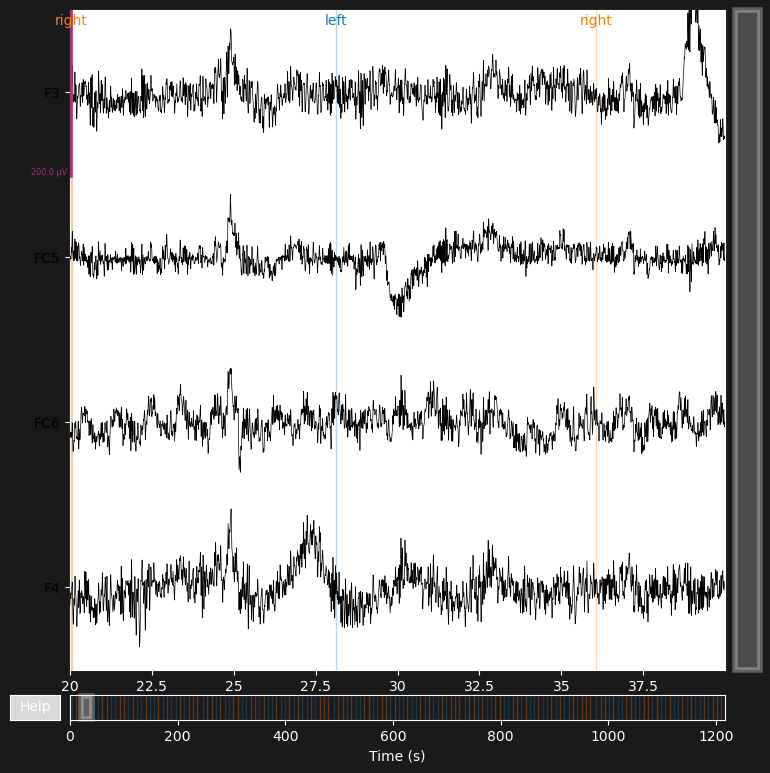

In [4]:
start_sec = 20
end_sec = 40

# Use a wider browser so the channel labels remain visible on the left.
mne.viz.set_browser_backend("matplotlib")
plot_channels = [c for c in ["FC5", "FC6", "F3", "F4"] if c in ch_names_raw]

# Keep every trial in the same class the same color.
annotation_colors = {
    description: (
        "tab:blue" if description == "left"
        else "tab:orange" if description == "right"
        else "tab:gray"
    )
    for description in raw.annotations.description
    if description in {"left", "right"}
}

fig = raw.plot(
    start=start_sec,
    duration=end_sec - start_sec,
    picks=plot_channels,
    n_channels=len(plot_channels),
    scalings=dict(eeg=100e-6),
    annotation_colors=annotation_colors,
)
plt.show()

### Channel Locations (Montage)

So far MNE only knows channel *names*, not where they sit on the scalp. A **montage**
attaches 3-D sensor coordinates to each name, which unlocks topographic (scalp-map)
plotting. All 14 EPOC X channel names are standard 10-20 labels, so MNE's built-in
`standard_1020` montage covers them directly — no manual coordinates needed.

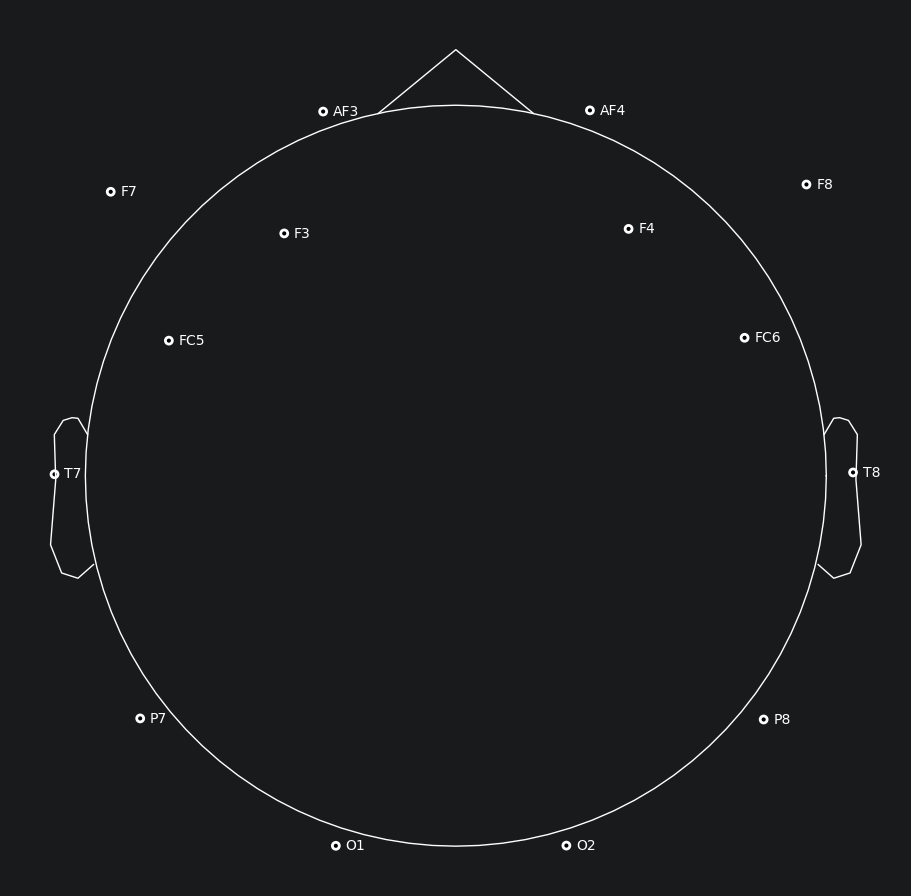

In [5]:
raw.set_montage("standard_1020")
raw.plot_sensors(show_names=True, sphere="auto")
plt.show()

### Power Spectral Density (PSD)

The time-domain plot tells us little about *which* frequencies dominate. `compute_psd()`
runs Welch's method per channel and `.plot()` overlays them. Expect a strong low-frequency
slope (1/f-like) and — since we haven't notch-filtered yet — a spike at **50 Hz** (Tokyo mains
frequency) and its harmonic near 100 Hz. (Here we cannot see a spike at 50 Hz since Emotive automatically applies notch filter before saving EEG data)

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


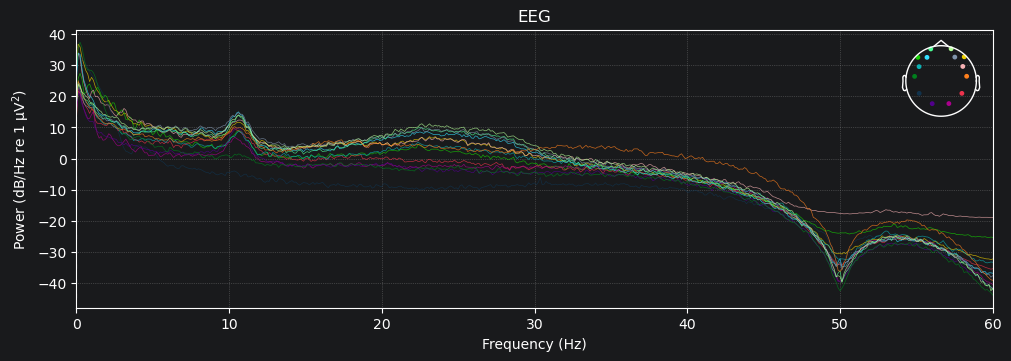

In [6]:
spectrum = raw.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

## 2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch

Section 1 concatenated all sessions into one continuous `raw`. We preprocess that
concatenated Raw directly. MNE inserts `BAD boundary` annotations between sessions, and
`reject_by_annotation=True` excludes any epoch that would cross a session boundary.

We apply, in order:
1. **`raw.notch_filter()`** — remove the 50 Hz mains-power noise
2. **`raw.filter()`** — retain the 1–40 Hz EEG frequency range
3. **`raw.set_eeg_reference("average")`** — Common Average Reference (CAR)
4. **`mne.events_from_annotations()` + `mne.Epochs`** — cut out each 4-second MI trial

### 2-1. Remove Noise

In [7]:
# === Preprocessing controls ===
# NOTCH_HZ: remove electrical mains noise at this frequency.
# Use 50.0 in Japan/Europe, 60.0 in North America, or None to disable it.
NOTCH_HZ = 50.0

# BANDPASS_HZ = (low, high): retain EEG frequencies between low and high Hz.
# The default 1–40 Hz range removes slow drifts and attenuates high-frequency noise.
# Examples: (8.0, 30.0) for mu + beta, or (8.0, 13.0) for mu only.
BANDPASS_HZ = (1.0, 40.0)

# APPLY_CAR: True applies Common Average Reference across all EEG channels.
# Set it to False to keep the original channel references.
APPLY_CAR = True

In [8]:
eeg = raw.copy()
# remove line noise
if NOTCH_HZ is not None:
    eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")
# bandpass filter EEG
eeg.filter(l_freq=BANDPASS_HZ[0], h_freq=BANDPASS_HZ[1], picks="eeg")
# apply common average reference
if APPLY_CAR:
    eeg.set_eeg_reference("average")

Let's check the effect of filtering and CAR on the raw signal with PSD.

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


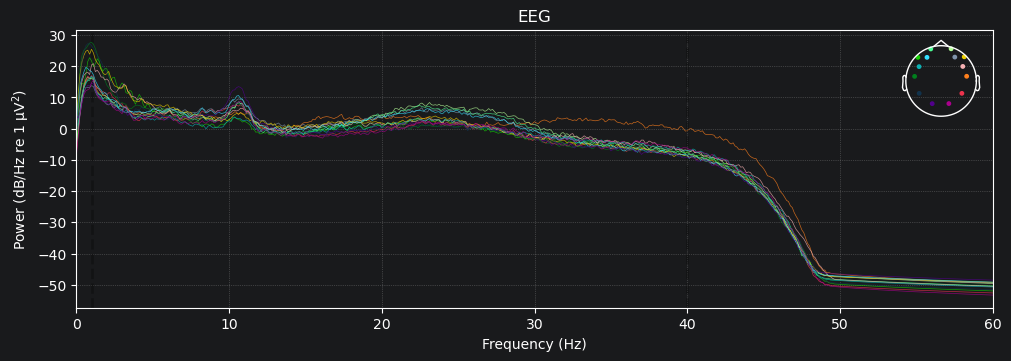

In [9]:
# Power Spectral Density (PSD)
spectrum = eeg.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

### 2-2. Epoch (cut out trials)

#### Extract and inspect events

- Convert the trial annotations into Left and Right event IDs, then plot their timing across the recording.

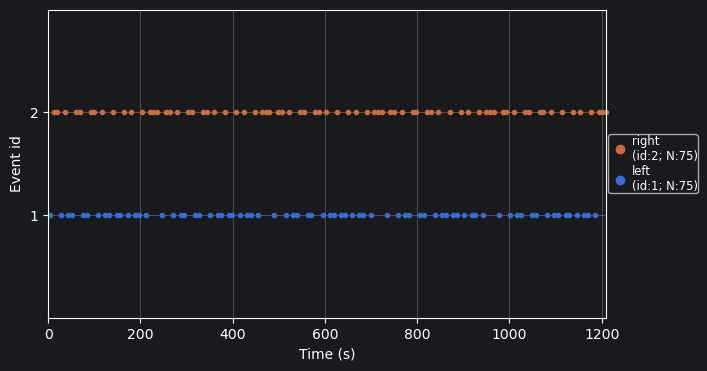

In [10]:
event_dict = {"left": 1, "right": 2}
events, _ = mne.events_from_annotations(eeg, event_id=event_dict)

# Plot the timing and class of all detected trials.
mne.viz.plot_events(
    events,
    sfreq=eeg.info["sfreq"],
    first_samp=eeg.first_samp,
    event_id=event_dict,
)
plt.show()

#### Create epochs

- Extract each trial from **−4 to +4 seconds** relative to MI onset: rest from −4 to −1 s,
  cue from −1 to 0 s, and MI from 0 to +4 s.

In [11]:
epochs = mne.Epochs(
    eeg,
    events,
    event_id=event_dict,
    tmin=-4.0,
    tmax=4.0,
    baseline=None,
    picks="eeg",
    preload=True,
    reject_by_annotation=True,
)

epochs

<Epochs | 150 events (all good), -4 – 4 s (baseline off), ~32.9 MiB, data loaded,
 'left': 75
 'right': 75>

## 3. Inspect Preprocessed Signals and Reject Bad Trials

The recording has 14 EPOC X channels. The figure below maps the headset channel names to
the brain regions underneath.

| EPOC X channel locations | Motor cortex location |
|---|---|
| ![EPOC X channel placement](assets/epoc_channel_locations.png) | ![Motor cortex region](assets/motor_cortex_regions.png) |

_Source: [channel locations](https://www.researchgate.net/figure/Emotiv-EPOC-headset-14-channel-placement-with-two-reference-channels_fig2_309427804) · [motor cortex](https://www.researchgate.net/figure/Primary-brain-regions-Motor-cortex-is-the-region-in-charge-of-planning-control-and_fig2_331905251)._

Inspect every channel in each trial and record trials containing large artifacts or unstable signals.

### Inspect one trial

Set `trial` to an epoch index (starting from 0). Set `channels` to a list of channel names to limit the display, or `None` to display all EEG channels. The red vertical line marks the motor-imagery onset at 0 s.

Trial index: 4


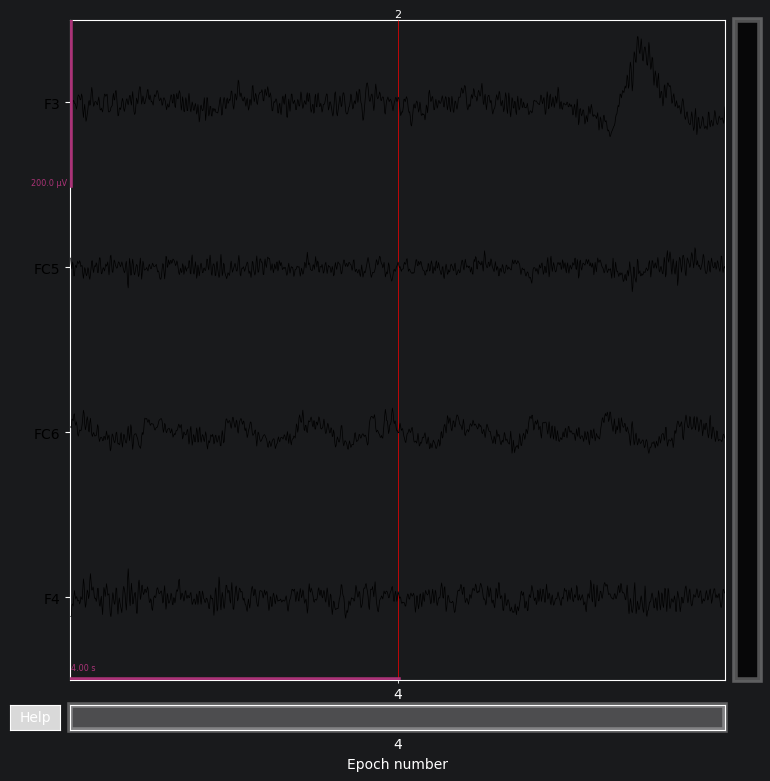

In [12]:
trial = 4
# channels = None  # e.g. ["FC5", "FC6", "F3", "F4"]
channels = ["FC5", "FC6", "F3", "F4"]

selected_channels = epochs.ch_names if channels is None else channels
print(f"Trial index: {trial}")
epochs[trial].plot(
    n_epochs=1,
    picks=selected_channels,
    n_channels=len(selected_channels),
    scalings={"eeg": 100e-6},
    events=True,
    event_color="red",
)
plt.show()

### Mark bad trials

A few high-amplitude trials (movement / blink artifacts) carry so much power that they
dominate the trial-averaged power in Section 4 and bury the ERD/ERS. We flag them
**automatically**: any trial whose overall variance exceeds `THRESHOLD_K` times the median
trial is marked bad. Add any extra indices you spot by eye to `bad_trial_list`.

In [13]:
# Auto-detect artifact trials: those whose variance is far above the typical trial.
THRESHOLD_K = 2  # lower = stricter (rejects more trials)

trial_power = epochs.get_data().var(axis=(1, 2))  # one power value per trial
auto_bad = np.where(trial_power > np.median(trial_power) * THRESHOLD_K)[0]

# Add any extra trials you flagged by eye, e.g. extra_bad = [3, 18]
extra_bad = []
bad_trial_list = sorted(set(auto_bad.tolist()) | set(extra_bad))
print(f"Bad trials: {bad_trial_list}")

Bad trials: [6, 10, 11, 12, 20, 27, 37, 52, 53, 59, 73, 82, 83, 95, 126, 133]


### Remove bad trials

Create a cleaned copy after removing the selected trials.

In [14]:
epochs_clean = epochs.copy()
epochs_clean.drop(bad_trial_list, reason="USER")

print(f"Before: {len(epochs)} trials")
print(f"After : {len(epochs_clean)} trials")

Before: 150 trials
After : 134 trials


## 4. Decoding with DL (EEGNet, EEG-Conformer)

| Metric | What it measures | Chance |
|---|---|---|
| **Accuracy** | fraction of trials predicted correctly | 0.50 |
| **Balanced Accuracy** | mean of per-class recall — unaffected by class imbalance | 0.50 |
| **Cohen's κ** | agreement corrected for chance (1 = perfect, 0 = chance) | 0.00 |

### 4-0. Shared setup

The DL signal is rebuilt from raw data with a 1–40 Hz bandpass and CAR, then the common bad
trials found in Section 3 are removed. EEGNet and EEG-Conformer share these inputs and folds.

In [15]:
import torch
from braindecode import EEGClassifier
from braindecode.models import EEGNet, EEGConformer
from skorch.helper import predefined_split
from skorch.dataset import Dataset
from skorch.callbacks import LRScheduler

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")

# === DL-specific preprocessing: 1-40 Hz -> CAR -> epoch -> common bad trials ===
DL_BANDPASS_HZ = (1.0, 40.0)
decoding_eeg = raw.copy()
if NOTCH_HZ is not None:
    decoding_eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")
decoding_eeg.filter(*DL_BANDPASS_HZ, picks="eeg")
decoding_eeg.set_eeg_reference("average", projection=False)

decoding_epochs = mne.Epochs(
    decoding_eeg, events, event_id=event_dict, tmin=-4.0, tmax=4.0,
    baseline=None, picks="eeg", preload=True, reject_by_annotation=True,
)
assert np.array_equal(decoding_epochs.events, epochs.events)
decoding_epochs.drop(bad_trial_list, reason="COMMON_BAD_TRIAL")
assert np.array_equal(decoding_epochs.events, epochs_clean.events)
epochs_mi = decoding_epochs.copy().crop(tmin=0.0, tmax=4.0)

X = epochs_mi.get_data(picks="eeg").astype("float32") * 1e6
y = epochs_mi.events[:, -1] - 1
trial_ids = np.arange(len(y))
n_chans, n_times = X.shape[1:]

# Same splitter and seed as ML. Identical labels in identical order imply identical folds.
CV_SEED = 0
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED)
folds = list(cv.split(X, y))
fold_id = np.empty(len(y), dtype=int)
for k, (_, test_idx) in enumerate(folds):
    fold_id[test_idx] = k


def evaluate(name, y_true, y_pred):
    scores = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
    }
    print(f"{name:10s} | acc={scores['accuracy']:.3f}"
          f" | balanced acc={scores['balanced_accuracy']:.3f}"
          f" | Cohen's κ={scores['cohen_kappa']:+.3f}")
    return scores


def misclassified(y_true, y_pred):
    wrong = np.flatnonzero(y_true != y_pred)
    return pd.DataFrame({
        "trial_id": trial_ids[wrong],
        "fold": fold_id[wrong],
        "true": [U.LABEL_NAMES[c] for c in y_true[wrong]],
        "predicted": [U.LABEL_NAMES[c] for c in y_pred[wrong]],
    })


print(f"DL preprocessing: {DL_BANDPASS_HZ[0]:g}-{DL_BANDPASS_HZ[1]:g} Hz, CAR")
print(f"Common bad trials removed: {len(bad_trial_list)}; retained: {len(epochs_mi)}")
print("Training device:", device)
print(f"Input: {X.shape} | labels: {np.bincount(y).tolist()}")
print(f"Fold test sizes: {np.bincount(fold_id).tolist()}")

DL preprocessing: 1-40 Hz, CAR
Common bad trials removed: 16; retained: 134
Training device: mps
Input: (134, 14, 1025) | labels: [67, 67]
Fold test sizes: [27, 27, 27, 27, 26]


In [31]:
N_EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 1e-5


def train_cv_dl(model_cls, model_name, **module_kwargs):
    """Train one fresh network per fold and return held-out predictions and histories."""
    y_pred = np.empty(len(y), dtype=int)
    histories = []

    for fold, (train_idx, test_idx) in enumerate(folds):
        torch.manual_seed(CV_SEED + fold)
        valid_ds = Dataset(X[test_idx], y[test_idx])
        net = EEGClassifier(
            model_cls,
            module__n_chans=n_chans,
            module__n_outputs=2,
            module__n_times=n_times,
            **module_kwargs,
            optimizer=torch.optim.Adam,
            lr=LEARNING_RATE,
            max_epochs=N_EPOCHS,
            batch_size=BATCH_SIZE,
            train_split=predefined_split(valid_ds),
            callbacks=[("lr", LRScheduler("CosineAnnealingLR", T_max=N_EPOCHS - 1))],
            device=device,
            verbose=0,
        )
        net.fit(X[train_idx], y[train_idx])
        y_pred[test_idx] = net.predict(X[test_idx])
        histories.append(net.history)
        print(f"Fold {fold}: train_loss={net.history[-1, 'train_loss']:.3f}"
              f" | valid_loss={net.history[-1, 'valid_loss']:.3f}")

    return y_pred, evaluate(model_name, y, y_pred), histories


def analyze_dl(model_name, y_pred, scores, histories):
    """Plot learning curves and confusion matrix, then list missed trials."""
    fig, axes = plt.subplots(1, len(histories), figsize=(16, 3), sharey=True)
    for fold, (ax, history) in enumerate(zip(axes, histories)):
        ax.plot(history[:, "epoch"], history[:, "train_loss"], label="train")
        ax.plot(history[:, "epoch"], history[:, "valid_loss"], label="valid")
        ax.set(title=f"Fold {fold}", xlabel="epoch")
    axes[0].set_ylabel("loss")
    axes[0].legend()
    fig.suptitle(f"{model_name} learning curves")
    plt.tight_layout()
    plt.show()

    ConfusionMatrixDisplay.from_predictions(
        y, y_pred, display_labels=[U.LABEL_NAMES[0], U.LABEL_NAMES[1]], cmap="Blues")
    plt.title(f"{model_name} — acc={scores['accuracy']:.2f}, "
              f"κ={scores['cohen_kappa']:+.2f}")
    plt.tight_layout()
    plt.show()

    mis = misclassified(y, y_pred)
    print(f"{model_name} misclassified {len(mis)} / {len(y)} trials")
    display(mis)
    return mis

#### 4-1 EEGNet

**EEGNet** is a compact convolutional network designed for EEG: a first layer of temporal
convolutions learns frequency-selective filters, and a depthwise spatial convolution learns
CSP-like spatial filters — end-to-end, with only a few thousand parameters.

##### 4-1-1 Evaluate the model

We run EEGNet through the shared 5-fold loop: a fresh net per fold, predicting its held-out
trials. On a GPU (Colab: *Runtime > Change runtime type > GPU*) this takes seconds; on CPU, a
minute or two.

In [32]:
y_pred_net, scores_net, hist_net = train_cv_dl(EEGNet, "EEGNet")

Fold 0: train_loss=0.710 | valid_loss=0.707
Fold 1: train_loss=0.674 | valid_loss=0.720
Fold 2: train_loss=0.689 | valid_loss=0.697
Fold 3: train_loss=0.727 | valid_loss=0.700
Fold 4: train_loss=0.733 | valid_loss=0.701
EEGNet     | acc=0.440 | balanced acc=0.440 | Cohen's κ=-0.119


##### 4-1-2 Analysis

Three views: the **learning curves** (do the folds learn, or just overfit?), the overall
**confusion matrix**, and the **trial IDs** EEGNet got wrong — kept for the model-vs-model
comparison across models.

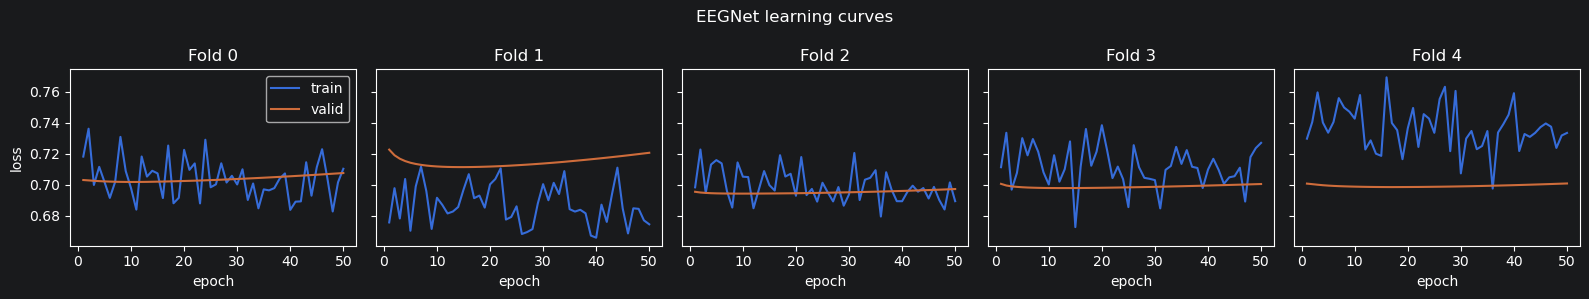

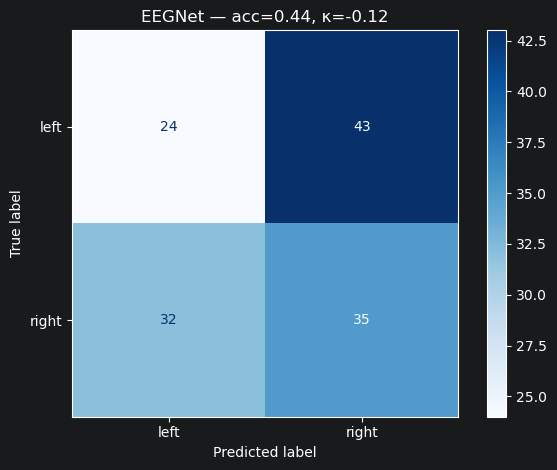

EEGNet misclassified 75 / 134 trials


,trial_id,fold,true,predicted
0,0,1,left,right
1,4,2,right,left
2,6,0,right,left
3,8,2,left,right
4,11,3,left,right
...,...,...,...,...
70,122,4,left,right
71,123,4,left,right
72,127,4,left,right
73,130,3,left,right


In [33]:
mis_net = analyze_dl("EEGNet", y_pred_net, scores_net, hist_net)

#### 4-2 EEG-Conformer

**EEG-Conformer** keeps a convolutional front-end (temporal + spatial filters, like EEGNet) but
then adds a **Transformer**: self-attention lets the model compare *different time segments* of
the trial and weigh where the informative μ/β desynchronization occurs, instead of treating every
moment equally. It has many more parameters than EEGNet, so on this small dataset expect it to overfit
even harder — a useful contrast to read off the learning curves.

##### 4-2-1 Evaluate the model

The same loop and the same folds — only the model class changes. `module__final_fc_length="auto"`
lets braindecode size the classifier head to our trial length automatically.

In [34]:
# Same CV loop as EEGNet; only the architecture differs. 'auto' sizes the Conformer's final
# fully-connected layer to n_times (its convolutional front-end determines the sequence length).
y_pred_conf, scores_conf, hist_conf = train_cv_dl(
    EEGConformer, "Conformer", module__final_fc_length="auto")

Fold 0: train_loss=0.696 | valid_loss=0.694
Fold 1: train_loss=0.699 | valid_loss=0.705
Fold 2: train_loss=0.740 | valid_loss=0.714
Fold 3: train_loss=0.731 | valid_loss=0.694
Fold 4: train_loss=0.712 | valid_loss=0.698
Conformer  | acc=0.500 | balanced acc=0.500 | Cohen's κ=+0.000


##### 4-2-2 Analysis

The same three views as EEGNet — read the learning curves for the (likely stronger) overfitting
that comes with the Conformer's larger capacity.

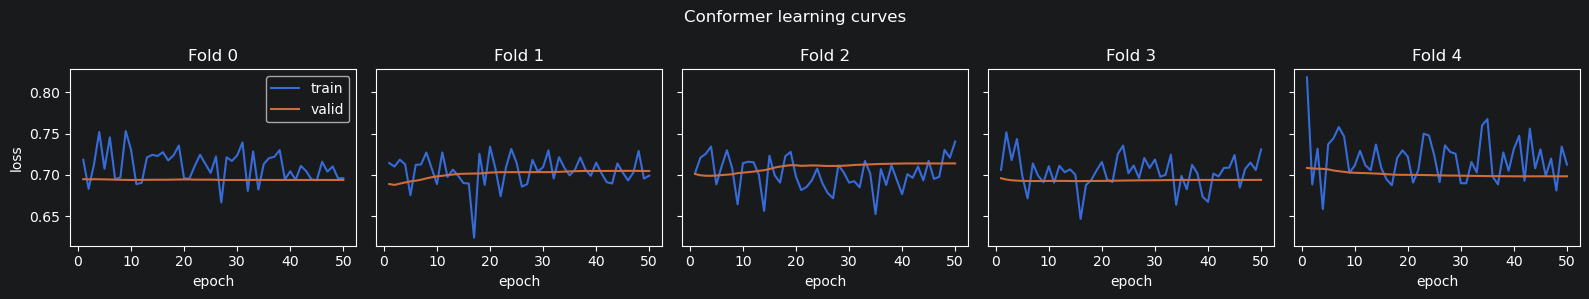

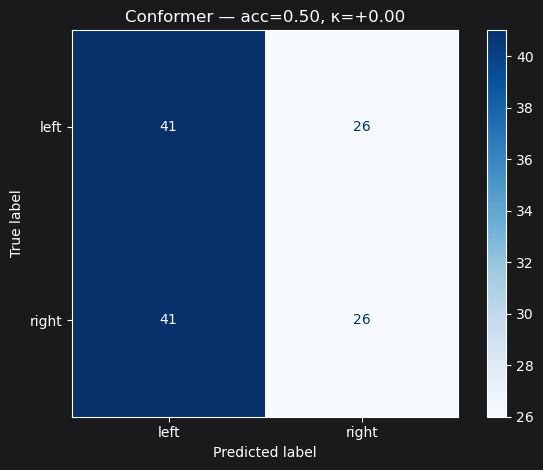

Conformer misclassified 67 / 134 trials


,trial_id,fold,true,predicted
0,0,1,left,right
1,2,0,right,left
2,4,2,right,left
3,6,0,right,left
4,7,2,right,left
...,...,...,...,...
62,126,2,right,left
63,129,2,right,left
64,131,4,right,left
65,132,3,right,left


In [35]:
mis_conf = analyze_dl("Conformer", y_pred_conf, scores_conf, hist_conf)